# Visualizations

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## pred loading

In [6]:
df = pd.read_csv("../data/predictions/pred_tweets.csv")
df.head(10)

,text,label,predicted_scores,predicted_label
0,$BYND - JPMorgan reels in expectations on Beyo...,negative,"{'negative': 0.7128058671951294, 'positive': 0...",negative
1,$CCL $RCL - Nomura points to bookings weakness...,negative,"{'negative': 0.9685064554214478, 'neutral': 0....",negative
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",negative,"{'negative': 0.9608473777770996, 'positive': 0...",negative
3,$ESS: BTIG Research cuts to Neutral https://t....,negative,"{'neutral': 0.5311363935470581, 'negative': 0....",neutral
4,$FNKO - Funko slides after Piper Jaffray PT cu...,negative,"{'negative': 0.935271680355072, 'neutral': 0.0...",negative
5,$FTI - TechnipFMC downgraded at Berenberg but ...,negative,"{'neutral': 0.6857630014419556, 'negative': 0....",neutral
6,$GM - GM loses a bull https://t.co/tdUfG5HbXy,negative,"{'negative': 0.8817174434661865, 'neutral': 0....",negative
7,$GM: Deutsche Bank cuts to Hold https://t.co/7...,negative,"{'neutral': 0.6673195958137512, 'negative': 0....",neutral
8,$GTT: Cowen cuts to Market Perform,negative,"{'negative': 0.4460240602493286, 'neutral': 0....",negative
9,$HNHAF $HNHPD $AAPL - Trendforce cuts iPhone e...,negative,"{'negative': 0.8111319541931152, 'neutral': 0....",negative


In [9]:
# example column names
# text, label, predicted_scores, predicted_label

df = df.copy()

# convert dict-like strings to real dicts if needed
def parse_scores(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        # handle strings like "{'negative': 0.71, 'positive': 0.18}"
        try:
            return eval(x)
        except:
            return {}
    return {}

df["predicted_scores"] = df["predicted_scores"].apply(parse_scores)

# ensure label order
classes = ["negative", "neutral", "positive"]

# unpack score dictionary into columns
for c in classes:
    df[c] = df["predicted_scores"].apply(lambda d: float(d.get(c, 0.0)))

df["pred_top_score"] = df[classes].max(axis=1)
df["predicted_label"] = df[classes].idxmax(axis=1)

## confusion matrix

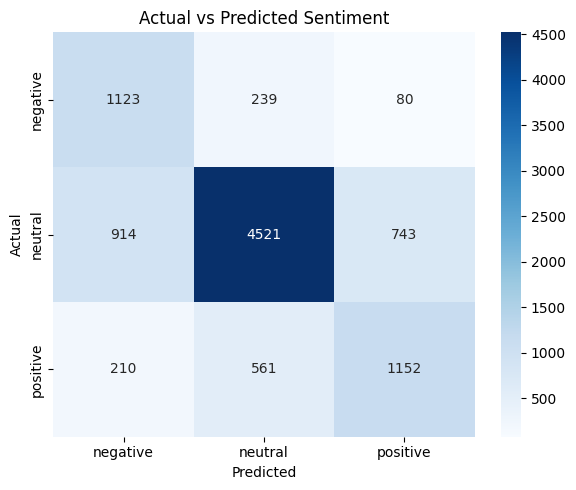

In [10]:
cm = pd.crosstab(df["label"], df["predicted_label"]).reindex(
    index=classes, columns=classes, fill_value=0
)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Actual vs Predicted Sentiment")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## class distribution

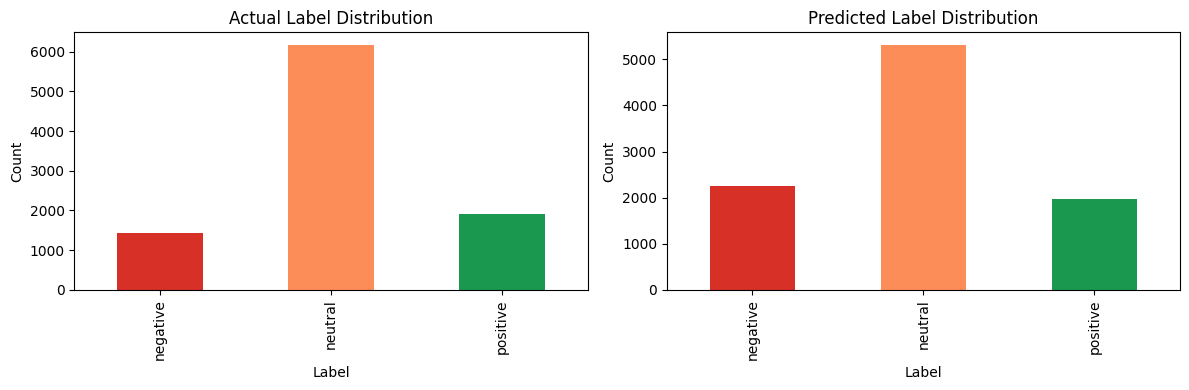

In [11]:
actual_counts = df["label"].value_counts().reindex(classes, fill_value=0)
pred_counts = df["predicted_label"].value_counts().reindex(classes, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

actual_counts.plot(kind="bar", ax=axes[0], color=["#d73027", "#fc8d59", "#1a9850"])
axes[0].set_title("Actual Label Distribution")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")

pred_counts.plot(kind="bar", ax=axes[1], color=["#d73027", "#fc8d59", "#1a9850"])
axes[1].set_title("Predicted Label Distribution")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

## confidence histogram

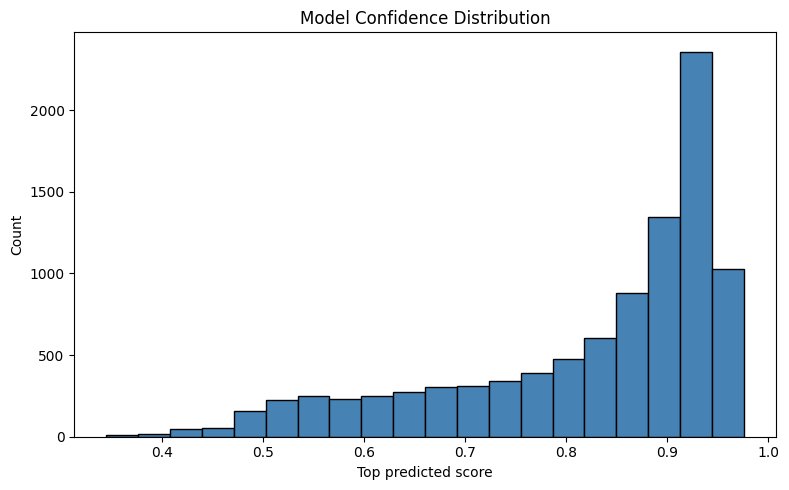

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(df["pred_top_score"], bins=20, edgecolor="black", color="steelblue")
plt.title("Model Confidence Distribution")
plt.xlabel("Top predicted score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## confid by label

/tmp/ipykernel_52719/1117969367.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="predicted_label", y="pred_top_score", order=classes, palette="Set2")


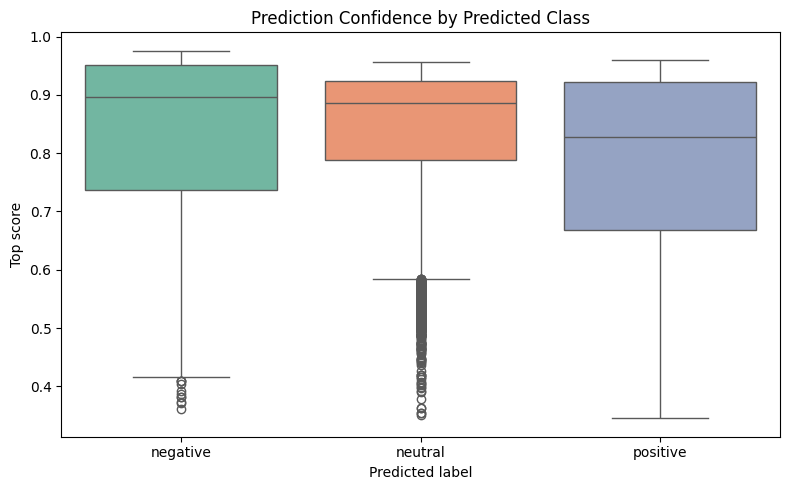

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="predicted_label", y="pred_top_score", order=classes, palette="Set2")
plt.title("Prediction Confidence by Predicted Class")
plt.xlabel("Predicted label")
plt.ylabel("Top score")
plt.tight_layout()
plt.show()

## missclassified examples

In [14]:
mis = df[df["label"] != df["predicted_label"]][[
    "text", "label", "predicted_label", "pred_top_score"
]].sort_values("pred_top_score", ascending=False)

print(mis.head(10))

                                                   text     label  \
433   Commercial and industrial loans at all commerc...   neutral   
3623  Tyson Foods Q1 beef sales fell 8% to $3.84 bln...   neutral   
1786  PNB Under-Reported Bad Loans By Rs 2,617 Crore...   neutral   
6902  Stock Market Update: Wholesale inventories dec...  positive   
6426  U.S. trade deficit in goods drops to $63.2 bil...  positive   
6439  12-month rate of core PPI slips to 3-year low ...   neutral   
7087  Stocks That Fell to 3-Year Lows in the Week of...   neutral   
4387  Divestment Will Lead To Loss Of Jobs, Says Con...   neutral   
6519  India's October 1-November 15 sugar output dow...   neutral   
7103  U.S. stocks end higher Friday, but S&P 500 suf...   neutral   

     predicted_label  pred_top_score  
433         negative        0.975982  
3623        negative        0.975574  
1786        negative        0.974025  
6902        negative        0.973877  
6426        negative        0.973860  
6439  

### wordcloud for missclassifications 

[('https', 1415), ('are', 142), ('new', 131), ('says', 130), ('china', 118), ('economy', 104), ('deal', 93), ('its', 91), ('hedge', 91), ('funds', 90), ('marketscreener', 88), ('billion', 83), ('buy', 82), ('inc', 81), ('trade', 79), ('fed', 78), ('year', 77), ('revenue', 75), ('beats', 73), ('bank', 70), ('oil', 70), ('update', 67), ('trump', 67), ('markets', 66), ('coronavirus', 64), ('eps', 64), ('down', 55), ('week', 54), ('2020', 53), ('business', 53)]


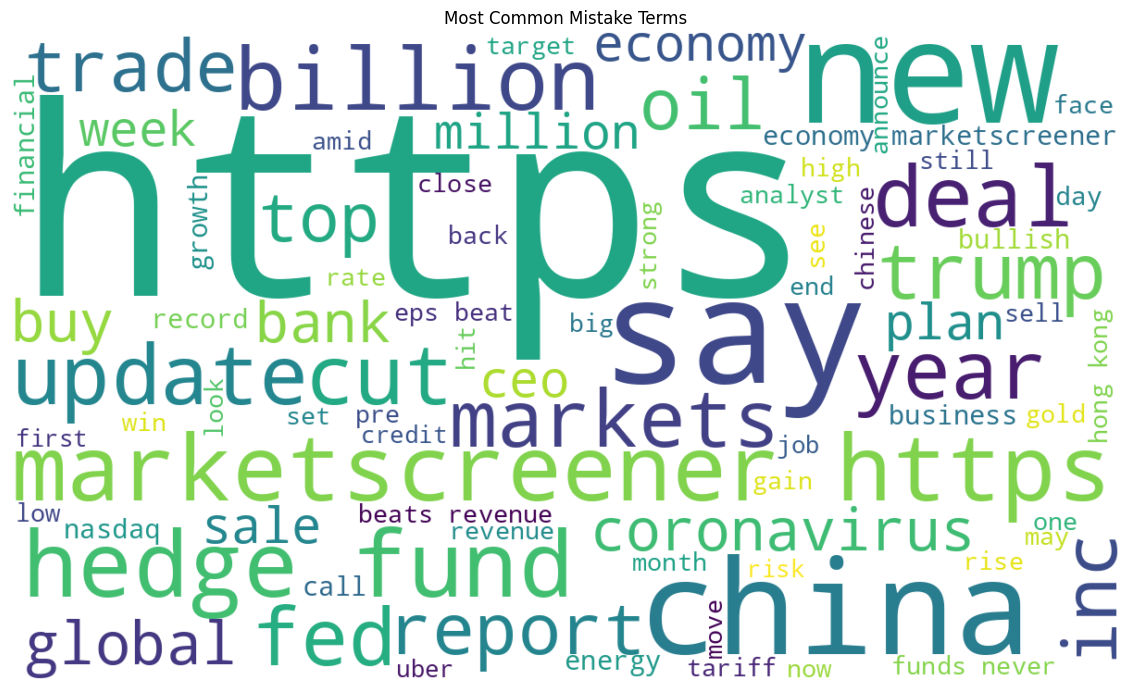

In [ ]:
import re
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# keep only mistakes
mis = df[df["label"] != df["predicted_label"]].copy()

# clean text
mis["text_clean"] = (
    mis["text"]
    .fillna("")
    .astype(str)
    .str.lower()
    .apply(lambda s: re.sub(r"[^a-z0-9\s]", " ", s))
    .apply(lambda s: re.sub(r"\s+", " ", s).strip())
)

# optional stopwords for finance tweets
stopwords = {
    "the","and","for","with","from","that","this","into","over","more",
    "have","has","was","were","not","but","about","their","them","they",
    "stock","stocks","market","prices","price","company","companies",
    "investors","investor","shares","share","earnings","results","said",
    "will","could","should","just","today","yesterday","after","before"
}

# flatten into tokens
tokens = []
for txt in mis["text_clean"]:
    tokens.extend([t for t in txt.split() if t not in stopwords and len(t) > 2])

# show top words
top_words = Counter(tokens).most_common(30)
print(top_words)

# create word cloud
text_for_cloud = " ".join(tokens)
wc = WordCloud(
    width=1200,
    height=700,
    background_color="white",
    colormap="viridis",
    max_words=80,
    random_state=42
).generate(text_for_cloud)

plt.figure(figsize=(12, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most Common Mistake Terms")
plt.tight_layout()
plt.show()